In [1]:
import torch
import numpy as np

from sklearn.metrics import accuracy_score, classification_report
from sklearn.linear_model import LogisticRegression

import os

import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
from cmcrameri import cm


# Configure matplotlib to use LaTeX for r'' strings while keeping other text unchanged
mpl.rcParams.update({
    'text.usetex': True,          # Use LaTeX for r'' strings
    'font.family': 'sans-serif',  # Default font family for regular text
    'mathtext.fontset': 'dejavusans',  # Font for math not using r''
    'axes.formatter.use_mathtext': False  # Enable math text for tick labels
})

In [2]:
# set random seed
def set_seed(seed):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ['PYTHONHASHSEED'] = str(seed)
set_seed(42)

In [3]:
from repl.networks.utils import prepare_model

In [4]:
def warn(*args, **kwargs):
    pass
import warnings
warnings.warn = warn

In [5]:
savedir = '../RPL_figures/6_successor_representations'
if not os.path.exists(savedir):
    os.makedirs(savedir)

# Data generation

In [6]:
# Data is the sequence "ABCD". each letter is one-hot encoded.
A_code = np.array([1, 0, 0, 0], dtype=np.float32)
B_code = np.array([0, 1, 0, 0], dtype=np.float32)
C_code = np.array([0, 0, 1, 0], dtype=np.float32)
D_code = np.array([0, 0, 0, 1], dtype=np.float32)
data_sequence = np.array([A_code, B_code, C_code, D_code], dtype=np.float32)  # shape: (L, C)
data_sequence.shape

(4, 4)

In [7]:
# create a dataloader for the sequence
from torch.utils.data import Dataset, DataLoader

class SequenceDataset(Dataset):
    """Dataset wrapper for a single sequence repeated n_trials times.
    
    Args:
        sequence (np.array): The input sequence of shape (L, C).
        n_trials (int): Number of times to repeat the sequence.
    """
    def __init__(self, sequence, n_trials=1):
        self.sequence = sequence
        self.n_trials = n_trials
        self.sequence = np.tile(self.sequence, (n_trials, 1, 1))  # shape: (n_trials, L, C)
        self.sequence = torch.tensor(self.sequence, dtype=torch.float32)  # convert to tensor

    def __len__(self):
        return len(self.sequence)

    def __getitem__(self, idx):
        return self.sequence[idx], torch.tensor([0, 1, 2, 3])

# create dataloader
sequence_dataset = SequenceDataset(data_sequence, n_trials=1)
sequence_dataloader = DataLoader(sequence_dataset, batch_size=1, shuffle=True)

# prepare RPL model

In [8]:
def train_model(model, dataloader, optimizer, criterion, num_epochs=10, 
                device='cpu', online_eval=False):
    """Train an RPL model on the provided dataloader.
    
    Args:
        model: The RPL model to train.
        dataloader: DataLoader providing training data.
        optimizer: Optimizer for training.
        criterion: Loss function.
        num_epochs (int): Number of training epochs.
        device (str): Device to use ('cpu' or 'cuda').
        online_eval (bool): Whether to perform online evaluation every 5 epochs.
        
    Returns:
        model: The trained model.
        train_loss_history: List of training loss values.
    """
    train_loss_history = []
    for epoch in range(num_epochs):
        total_loss = 0.0
        model.train()
        for batch, _ in dataloader:
            batch = batch.to(device)
            optimizer.zero_grad()
            z, c, p = model(batch)
            loss = criterion(z, p)
            train_loss_history.append(loss.item())
            total_loss += loss.item()
            loss.backward()
            optimizer.step()
        avg_loss = total_loss / len(dataloader)
        print(f"Epoch {epoch+1}/{num_epochs}, Training Loss: {avg_loss:.4f}")
        # Evaluate on test set
        if online_eval and (epoch + 1) % 5 == 0:
            evaluate_model(model, dataloader, criterion, device=device)
    return model, train_loss_history


def evaluate_model(model, dataloader, criterion, device='cpu'):
    """Evaluate the RPL model on the provided dataloader.

    Args:
        model: The RPL model to evaluate.
        dataloader: DataLoader providing evaluation data.
        criterion: Loss function.
        device (str): Device to use ('cpu' or 'cuda').

    Returns:
        avg_loss: Average loss over the evaluation dataset.
        sklearn_metrics: Dictionary of sklearn evaluation metrics.
    """
    model.eval()
    total_loss = 0.0
    with torch.no_grad():
        for batch, _ in dataloader:
            batch = batch.to(device)
            z, c, p = model(batch)
            loss = criterion(z, p)
            total_loss += loss.item()
    avg_loss = total_loss / len(dataloader)
    print(f"Average evaluation loss: {avg_loss:.4f}")
    sklearn_metrics = sklearn_eval_metrics(model, dataloader, 
                                           reps_to_eval=['ctx', 'pred', 'enc'], 
                                           device=device)
    return avg_loss, sklearn_metrics


def get_representations(model, dataloader, reps_to_eval=['ctx'], device='cpu'):
    """Extract representations from the model for the given dataloader.
    
    Args:
        model: The RPL model.
        dataloader: DataLoader providing data.
        reps_to_eval (list): List of representations to extract ('enc', 'ctx', 'pred').
        device (str): Device to use ('cpu' or 'cuda').
    
    Returns:
        reps: Dictionary of extracted representations.
        labels: Corresponding labels.
    """
    reps = {k: [] for k in reps_to_eval}
    labels_list = []
    model.eval()
    with torch.no_grad():
        for batch, labels in dataloader:
            batch = batch.to(device)
            z, c, p = model(batch)
            for rep in reps_to_eval:
                if rep == 'enc':
                    reps[rep].append(z.cpu().numpy())
                elif rep == 'ctx':
                    reps[rep].append(c.cpu().numpy())
                elif rep == 'pred':
                    reps[rep].append(p.cpu().numpy())
            labels_list.append(labels.cpu().numpy())
    for rep in reps_to_eval:
        reps[rep] = np.concatenate(reps[rep], axis=0)
    labels = np.concatenate(labels_list, axis=0)
    return reps, labels


def sklearn_eval_metrics(model, dataloader, reps_to_eval=['ctx'], device='cpu', print_report=False):
    """Evaluate representations using sklearn classification metrics.
    
    Args:
        model: The RPL model.
        dataloader: DataLoader providing data.
        reps_to_eval (list): List of representations to evaluate ('enc', 'ctx', 'pred').
        device (str): Device to use ('cpu' or 'cuda').
        print_report (bool): Whether to print the classification report.

    Returns:
        results: Dictionary of evaluation results for each representation.
            For each representation, contains `accuracy`, classification `report`, 
            and classifier (`clf`).
    """
    reps, labels = get_representations(model, dataloader, reps_to_eval=reps_to_eval, device=device)
    results = {k: {} for k in reps_to_eval}
    for rep in reps_to_eval:
        X = reps[rep].reshape((-1, reps[rep].shape[-1]))
        y = labels.flatten()
        clf = LogisticRegression(random_state=42)
        clf.fit(X, y)
        y_pred = clf.predict(X)
        acc = accuracy_score(y, y_pred)
        report = classification_report(y, y_pred, output_dict=True)
        results[rep]['accuracy'] = acc
        results[rep]['report'] = report
        results[rep]['clf'] = clf
        print(f"Evaluation on {rep} representation:")
        print(f"Accuracy: {acc:.4f}")
        if print_report:
            print("Classification Report:")
            print(classification_report(y, y_pred))
    return results


In [9]:
def get_models(enc_dim, ctx_dim, pred_hidden_dim, enc_n_layers, input_size=4, 
               n_models=10, init_enc=True, init_ctx=True, device='cpu'):
    """Create and initialize multiple RPL models.
    
    Args:
        enc_dim (int): Dimension of the encoder output.
        ctx_dim (int): Dimension of the context representation.
        pred_hidden_dim (int): Dimension of the predictor hidden layer.
        enc_n_layers (int): Number of layers in the encoder.
        input_size (int): Size of the input.
        n_models (int): Number of models to create.
        init_enc (bool): Whether to initialize the encoder weights.
        init_ctx (bool): Whether to initialize the integrator weights.
        device (str): Device to use ('cpu' or 'cuda').

    Returns:
        models (list): List of initialized RPL models.
    """
    models = []
    for i in range(n_models):
        model = prepare_model(
            encoder_kind="mlp",
            integrator_kind="rnn",
            predictor_kind="linear",
            input_size=input_size,
            n_in_channels=1,
            enc_dim=enc_dim,
            ctx_dim=ctx_dim,
            pred_n_hidden_layers=1,
            pred_hidden_dim=pred_hidden_dim,
            pred_steps=1,
            prediction_target="enc",
            use_bn_enc=False,
            enc_n_layers=enc_n_layers,
            preprocess=None,
            postprocess=None,
            flatten_enc_output=False,
            return_full_features=False,
        ).to(device)

        # freeze the encoder
        for name, param in model.named_parameters():
            if 'encoder' in name:
                param.requires_grad = False

        # initialize weights of the encoder with identity matrix
        if init_enc:
            for name, param in model.named_parameters():
                if 'encoder' in name and 'weight' in name:
                    print(f"Initializing {name} with identity matrix")
                    if param.dim() == 3:
                        torch.nn.init.eye_(param[:, :, 0])
                    elif param.dim() == 2:
                        torch.nn.init.eye_(param)
                elif 'encoder' in name and 'bias' in name:
                    # initialze biases with zeros
                    print(f"Initializing {name} with zeros")
                    torch.nn.init.zeros_(param)

        # initialize weights of the integrator (rnn) with identity matrix
        if init_ctx:
            for name, param in model.named_parameters():
                if 'integrator' in name and 'weight' in name:
                    print(f"Initializing {name} with identity matrix")
                    torch.nn.init.eye_(param)
                elif 'integrator' in name and 'bias' in name:
                    # initialze biases with zeros
                    print(f"Initializing {name} with zeros")
                    torch.nn.init.zeros_(param)

        # initialize weights of the predictor (linear) with small random values
        for name, param in model.named_parameters():
            if 'predictor' in name and 'weight' in name:
                print(f"Initializing {name} with small random values")
                torch.nn.init.xavier_uniform_(param)
            elif 'predictor' in name and 'bias' in name:
                # initialze biases with zeros
                print(f"Initializing {name} with zeros")
                torch.nn.init.zeros_(param)

        models.append(model)
    return models

In [10]:
def train_models(models, dataloader, num_epochs=1, lr=1e-3, weight_decay=1e-4,
                 pred_lr_mult=10, device='cpu'):
    """Train multiple RPL models on the provided dataloader.
    
    Args:
        models (list): List of RPL models to train.
        dataloader: DataLoader providing training data.
        num_epochs (int): Number of training epochs.
        lr (float): Learning rate.
        weight_decay (float): Weight decay for optimizer.
        pred_lr_mult (float): Learning rate multiplier for predictor.
        device (str): Device to use ('cpu' or 'cuda').

    Returns:
        trained_models (list): List of trained models.
        train_loss_histories (list): List of training loss histories for each model.
    """
    from repl.modules.criterion import PredLoss


    criterion = PredLoss(pred_steps=1, pred_loss_type="l2")

    trained_models = []
    train_loss_histories = []
    for model in models:
        params_predictor = [param for name, param in model.named_parameters() if param.requires_grad and "predictor" in name]
        params_encoder = [param for name, param in model.named_parameters() if param.requires_grad and "predictor" not in name]
        model_params = [
            {"params": params_predictor, "lr": lr * pred_lr_mult, "weight_decay": weight_decay},
            {"params": params_encoder, "lr": lr, "weight_decay": weight_decay}
        ]
        optimizer = torch.optim.AdamW(model_params)

        trained_model, train_loss_history = train_model(
            model, dataloader, optimizer=optimizer, criterion=criterion, num_epochs=num_epochs, device=device
        )
        trained_models.append(trained_model)
        train_loss_histories.append(train_loss_history)
    return trained_models, train_loss_histories

In [11]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [12]:
enc_dim = 4
ctx_dim = 4
pred_hidden_dim = 4
enc_n_layers = 1

# Training

In [13]:
pred_models = get_models(enc_dim, ctx_dim, pred_hidden_dim, enc_n_layers, 
                         input_size=4, n_models=35, init_enc=True, init_ctx=True, device=device)
trained_pred_models, train_loss_histories = train_models(pred_models, sequence_dataloader, 
                                                          num_epochs=352, lr=1e-3, weight_decay=1e-4,
                                                          pred_lr_mult=10, device=device)

Initializing encoder.backbone.layers.dense0.weight with identity matrix
Initializing encoder.backbone.layers.dense0.bias with zeros
Initializing integrator.backbone.weight_ih_l0 with identity matrix
Initializing integrator.backbone.weight_hh_l0 with identity matrix
Initializing integrator.backbone.bias_ih_l0 with zeros
Initializing integrator.backbone.bias_hh_l0 with zeros
Initializing predictor.layers.linear.weight with small random values
Initializing predictor.layers.linear.bias with zeros
Initializing encoder.backbone.layers.dense0.weight with identity matrix
Initializing encoder.backbone.layers.dense0.bias with zeros
Initializing integrator.backbone.weight_ih_l0 with identity matrix
Initializing integrator.backbone.weight_hh_l0 with identity matrix
Initializing integrator.backbone.bias_ih_l0 with zeros
Initializing integrator.backbone.bias_hh_l0 with zeros
Initializing predictor.layers.linear.weight with small random values
Initializing predictor.layers.linear.bias with zeros
Init

# Analysis

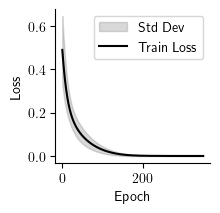

In [14]:
# plot training loss history
plt.figure(figsize=(2, 2))
mean_train_loss_history = np.mean(train_loss_histories, axis=0)
std_train_loss_history = np.std(train_loss_histories, axis=0)
plt.fill_between(range(len(mean_train_loss_history)), 
                 mean_train_loss_history - std_train_loss_history, 
                 mean_train_loss_history + std_train_loss_history, 
                 color='gray', alpha=0.3, label='Std Dev')
plt.plot(mean_train_loss_history, color="black", label='Train Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
sns.despine()
plt.show()

In [15]:
reps_to_eval = ['ctx', 'pred', 'enc']
sklearn_metrics_all = []
for i, model in enumerate(trained_pred_models):
    print(f"Model {i+1}:")
    sklearn_metrics = sklearn_eval_metrics(model, sequence_dataloader, reps_to_eval=reps_to_eval, device=device, print_report=False)
    sklearn_metrics_all.append(sklearn_metrics)

Model 1:
Evaluation on ctx representation:
Accuracy: 1.0000
Evaluation on pred representation:
Accuracy: 1.0000
Evaluation on enc representation:
Accuracy: 1.0000
Model 2:
Evaluation on ctx representation:
Accuracy: 1.0000
Evaluation on pred representation:
Accuracy: 1.0000
Evaluation on enc representation:
Accuracy: 1.0000
Model 3:
Evaluation on ctx representation:
Accuracy: 1.0000
Evaluation on pred representation:
Accuracy: 1.0000
Evaluation on enc representation:
Accuracy: 1.0000
Model 4:
Evaluation on ctx representation:
Accuracy: 1.0000
Evaluation on pred representation:
Accuracy: 1.0000
Evaluation on enc representation:
Accuracy: 1.0000
Model 5:
Evaluation on ctx representation:
Accuracy: 1.0000
Evaluation on pred representation:
Accuracy: 1.0000
Evaluation on enc representation:
Accuracy: 1.0000
Model 6:
Evaluation on ctx representation:
Accuracy: 1.0000
Evaluation on pred representation:
Accuracy: 1.0000
Evaluation on enc representation:
Accuracy: 1.0000
Model 7:
Evaluation on

In [16]:
# get weights from clf per representation
weights = {}
for rep in reps_to_eval:
    for i, sklearn_metrics in enumerate(sklearn_metrics_all):
        clf = sklearn_metrics[rep]['clf']
        if rep not in weights:
            weights[rep] = []
        weights[rep].append(clf.coef_.T)  # shape: (n_features, n_classes)

In [17]:
# find mapping between neurons and sequence elements
sequence_elements = ['A', 'B', 'C', 'D']
element2neuron = [{k: {s: [] for s in sequence_elements} for k in reps_to_eval} for _ in range(len(pred_models))]

for rep in reps_to_eval:
    for i, weight in enumerate(weights[rep]):
        weight = torch.from_numpy(weight).float().to(device)
        for j, W in enumerate(weight):
            max_idx = W.argmax().item()
            element2neuron[i][rep][sequence_elements[max_idx]].append(j)

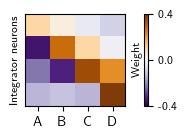

In [18]:
# sort weights based on the mapping
sorted_weights_ctx_neuron = []
for i, weight in enumerate(weights['ctx']):
    weight = torch.from_numpy(weight).float().to(device)
    sorted_weight = []
    for element in sequence_elements:
        neurons = element2neuron[i]['ctx'][element]
        for neuron in neurons:
            sorted_weight.append(weight[neuron, :].cpu().numpy())
    sorted_weights_ctx_neuron.append(np.stack(sorted_weight, axis=0))

# Plot the sorted weights for ctx
fig, ax = plt.subplots(1, 1, figsize=(1.6, 1.2))
weight = np.mean(sorted_weights_ctx_neuron, axis=0)
max_weight = max(-np.min(weight), np.max(weight))
ax.imshow(weight, cmap="PuOr_r", aspect='auto', vmin=-max_weight, vmax=max_weight)
# ax.set_title(f"Weights for pred")
ax.set_xticks([0, 1, 2, 3])
ax.set_xticklabels(['A', 'B', 'C', 'D'])
ax.set_yticks([])
ax.set_ylabel('Integrator neurons', fontsize=8)
cbar = plt.colorbar(ax.images[0], ax=ax, orientation='vertical', fraction=0.046, pad=0.15, format="%.1f")
cbar.set_label('Weight', rotation=90, labelpad=1, fontsize=8)
cbar.ax.yaxis.set_label_position('left')
cbar.ax.tick_params(labelsize=8)
cbar.ax.set_yticks([-max_weight, 0, max_weight])
fig.savefig(os.path.join(savedir, "SR_ctx_reg_weights.pdf"), bbox_inches='tight', dpi=300, transparent=True)

In [19]:
reps_idx = {'ctx': 1, 'pred': 2, 'enc': 0}

In [20]:
a_only_sequence = np.zeros((1, 4, 4), dtype=np.float32)
a_only_sequence[0, 0, :] = A_code
a_only_sequence = torch.tensor(a_only_sequence, dtype=torch.float32).to(device)

b_only_sequence = np.zeros((1, 4, 4), dtype=np.float32)
b_only_sequence[0, 1, :] = B_code
b_only_sequence = torch.tensor(b_only_sequence, dtype=torch.float32).to(device)

c_only_sequence = np.zeros((1, 4, 4), dtype=np.float32)
c_only_sequence[0, 2, :] = C_code
c_only_sequence = torch.tensor(c_only_sequence, dtype=torch.float32).to(device)

d_only_sequence = np.zeros((1, 4, 4), dtype=np.float32)
d_only_sequence[0, 3, :] = D_code
d_only_sequence = torch.tensor(d_only_sequence, dtype=torch.float32).to(device)

In [21]:
a_only_reps_all = []
b_only_reps_all = []
c_only_reps_all = []
d_only_reps_all = []
full_seq_reps_all = []
zero_reps_all = []

with torch.no_grad():
    for i, pred_model in enumerate(trained_pred_models):
        a_only_reps = pred_model(a_only_sequence)
        b_only_reps = pred_model(b_only_sequence)
        c_only_reps = pred_model(c_only_sequence)
        d_only_reps = pred_model(d_only_sequence)
        a_only_reps = [t.cpu().numpy() for t in a_only_reps]
        b_only_reps = [t.cpu().numpy() for t in b_only_reps]
        c_only_reps = [t.cpu().numpy() for t in c_only_reps]
        d_only_reps = [t.cpu().numpy() for t in d_only_reps]
        a_only_reps_all.append(a_only_reps)
        b_only_reps_all.append(b_only_reps)
        c_only_reps_all.append(c_only_reps)
        d_only_reps_all.append(d_only_reps)

        full_seq_reps = pred_model(sequence_dataset[0][0].unsqueeze(0).to(device))
        full_seq_reps = [t.cpu().numpy() for t in full_seq_reps]
        full_seq_reps_all.append(full_seq_reps)

        # response to zero input
        zero_input = torch.zeros((1, 4, 4), dtype=torch.float32).to(device)
        zero_reps = pred_model(zero_input)
        zero_reps = [t.cpu().numpy() for t in zero_reps]
        zero_reps_all.append(zero_reps)

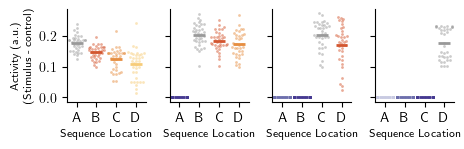

In [22]:
fig, ax = plt.subplots(1, 4, figsize=(5, 1.2), sharey=True)
colors = [["#999999", "#d35630", "#e68e41", "#f7cc79"],
          ["#453991", "#999999", "#d35630", "#e68e41"],
          ["#6d6fac", "#453991", "#999999", "#d35630"],
          ["#c8cae1", "#6d6fac", "#453991", "#999999"]]
rep_list = [a_only_reps_all, b_only_reps_all, c_only_reps_all, d_only_reps_all]
for i in range(4):
    for j in range(len(sequence_elements)):
        neuron_activities = []
        for model_idx in range(len(pred_models)):
            neuron_activities.append(rep_list[i][model_idx][reps_idx['ctx']][0,j, :].mean() - zero_reps_all[model_idx][reps_idx['ctx']][0,j, :].mean())
        sem = np.std(neuron_activities) / np.sqrt(len(neuron_activities))
        # swarm plot instead of bar plot
        # ax[i].bar(sequence_elements[j], np.mean(neuron_activities), yerr=sem, width=0.6, color=colors[i][j], alpha=0.5, zorder=1)
        ax[i].hlines(np.mean(neuron_activities), j-0.3, j+0.3, colors=colors[i][j], linewidth=2)
        sns.swarmplot(x=[sequence_elements[j]]*len(neuron_activities), y=neuron_activities, ax=ax[i], color=colors[i][j], size=2, alpha=0.5)
        # ax[i].scatter([sequence_elements[j]]*len(neuron_activities), neuron_activities, color='black', s=5, alpha=0.3)
    ax[i].set_xlabel('Sequence Location', fontsize=8)
ax[0].set_ylabel('Activity (a.u.)\n(Stimulus - control)', fontsize=8)
# increase space between subplots
plt.subplots_adjust(wspace=0.3)
sns.despine()
fig.savefig(os.path.join(savedir, "SR_partial_seqs_t.pdf"), bbox_inches='tight', dpi=300, transparent=True)

In [23]:
# Configure matplotlib to use LaTeX for r'' strings while keeping other text unchanged
mpl.rcParams.update({
    'text.usetex': True,          # Use LaTeX for r'' strings
    'font.family': 'sans-serif',  # Default font family for regular text
    'mathtext.fontset': 'dejavusans',  # Font for math not using r''
    'axes.formatter.use_mathtext': False  # Enable math text for tick labels
})

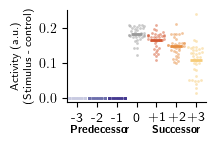

In [24]:
fig, ax = plt.subplots(1, 1, figsize=(1.8, 1.2))
colors = ["#c8cae1", "#6d6fac", "#453991", "#999999", "#d35630", "#e68e41", "#f7cc79"]
rep_list = [a_only_reps_all, b_only_reps_all, c_only_reps_all, d_only_reps_all]
neural_activities_per_time = np.zeros((35, 7)) # (n_models, time_points)
for model_idx in range(len(pred_models)):
    for el in range(4):
        for t in range(4):
            neurons = element2neuron[model_idx]['ctx'][sequence_elements[t]]
            if len(neurons) == 0:
                continue
            if el == t:
                neural_activities_per_time[model_idx, 3] += (rep_list[el][model_idx][reps_idx['ctx']][0, t, :] - zero_reps_all[model_idx][reps_idx['ctx']][0, t, :]).mean()
            elif el < t:
                neural_activities_per_time[model_idx, 3 + (t - el)] += (rep_list[el][model_idx][reps_idx['ctx']][0, t, :] - zero_reps_all[model_idx][reps_idx['ctx']][0, t, :]).mean()
            else:
                neural_activities_per_time[model_idx, 3 - (el - t)] += (rep_list[el][model_idx][reps_idx['ctx']][0, t, :] - zero_reps_all[model_idx][reps_idx['ctx']][0, t, :]).mean()
for i in range(7):
    sem = np.std(neural_activities_per_time[:, i] / (4 - np.abs(i - 3))) / np.sqrt(len(pred_models))
    # ax.bar(i, np.mean(neural_activities_per_time[:, i] / (4 - np.abs(i - 3))), yerr=sem, alpha=1.0, width=0.6, color=colors[i])
    #swarm plot instead of bar plot
    ax.hlines(np.mean(neural_activities_per_time[:, i] / (4 - np.abs(i - 3))), i-0.3, i+0.3, colors=colors[i], linewidth=2)
    sns.swarmplot(x=[i]*len(pred_models), y=neural_activities_per_time[:, i] / (4 - np.abs(i - 3)), ax=ax, color=colors[i], size=2, alpha=0.5)
# ax.set_xlabel('Time (a.u.)', fontsize=8)
ax.annotate(r"\textbf{Predecessor}", xy=(0, 0.), xytext=(-0.3, -0.1), fontsize=8)
ax.annotate(r"\textbf{Successor}", xy=(0, 0.), xytext=(3.8, -0.1), fontsize=8)
ax.set_xticks(range(7))
ax.set_xticklabels(['-3', '-2', '-1', '0', '+1', '+2', '+3'])
ax.set_ylabel('Activity (a.u.)\n(Stimulus - control)', fontsize=8)
# increase space between subplots
plt.subplots_adjust(wspace=0.4)
sns.despine()
fig.savefig(os.path.join(savedir, "SR_predecessor_successor_t.pdf"), bbox_inches='tight', dpi=300, transparent=True)